**NBA Elo EDA · Part 2 of 4.** Distributions, outliers and transformations.

**Dataset:** NBA All Elo (NBA & ABA game results with Elo ratings), [FiveThirtyEight](https://github.com/fivethirtyeight/data/tree/master/nba-elo), CC BY 4.0. Parts: [1](01_data_quality.ipynb) · [2](02_distributions_outliers.ipynb) · [3](03_bivariate.ipynb) · [4](04_groups_multivariate.ipynb)

# Part 2 — Distributions, Outliers and Transformations

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
%matplotlib inline

In [2]:
# Same dataset and loading logic as Part 1: use the local cache if it
# exists, otherwise download from the original public source.
DATA_URL = "https://raw.githubusercontent.com/fivethirtyeight/data/master/nba-elo/nbaallelo.csv"
CACHE_PATH = "data/nbaallelo.csv"

if os.path.exists(CACHE_PATH):
    df = pd.read_csv(CACHE_PATH)
else:
    df = pd.read_csv(DATA_URL)
    os.makedirs("data", exist_ok=True)
    df.to_csv(CACHE_PATH, index=False)

# A derived variable used throughout this analysis: the absolute margin of
# victory/defeat for a team in a single game (always >= 1, since every game
# in this dataset has a winner and a loser).
df["margin"] = df["pts"] - df["opp_pts"]
df["abs_margin"] = df["margin"].abs()

df.shape

(110902, 25)

## Choosing the Three Numerical Variables

From Part 1, the variables central to my exploratory questions were `pts` (scoring), `elo_i` (team skill rating), and the relationship between scoring and game context (home/away, playoffs, league). For this part I select:

1. **`pts`** — points scored by a team in a single game. Central to Part 1 questions about scoring trends over time and across leagues.
2. **`elo_i`** — the team's Elo rating going into the game. Central to Part 1's question about whether the Elo-based forecast predicts outcomes well.
3. **`abs_margin`** (derived: `|pts - opp_pts|`) — how many points the game was decided by. This connects directly to Part 1's home-advantage question (is home advantage about *winning*, or about *winning big*?), and — unlike `pts` and `elo_i`, which turned out to be close to symmetric — it is **noticeably right-skewed**, which makes it the natural candidate for the outlier and transformation work in Parts 3–6.

## Part 1: Exploring Distributions

In [3]:
def describe_variable(series):
    """Return the 8 required descriptive statistics for one numerical variable."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    return pd.Series({
        "mean": series.mean(),
        "median": series.median(),
        "min": series.min(),
        "max": series.max(),
        "Q1": q1,
        "Q3": q3,
        "std": series.std(),
        "IQR": q3 - q1,
    })

stats_table = pd.concat(
    {
        "pts": describe_variable(df["pts"]),
        "elo_i": describe_variable(df["elo_i"]),
        "abs_margin": describe_variable(df["abs_margin"]),
    },
    axis=1,
)
stats_table

,pts,elo_i,abs_margin
mean,103.229049,1492.730380,10.733873
median,103.000000,1498.820500,9.000000
min,0.000000,1091.644500,1.000000
max,186.000000,1853.104500,68.000000
Q1,93.000000,1415.690900,5.000000
Q3,113.000000,1572.473575,15.000000
std,15.104216,111.434163,7.947202
IQR,20.000000,156.782675,10.000000


### Variable 1: `pts` — points scored per game

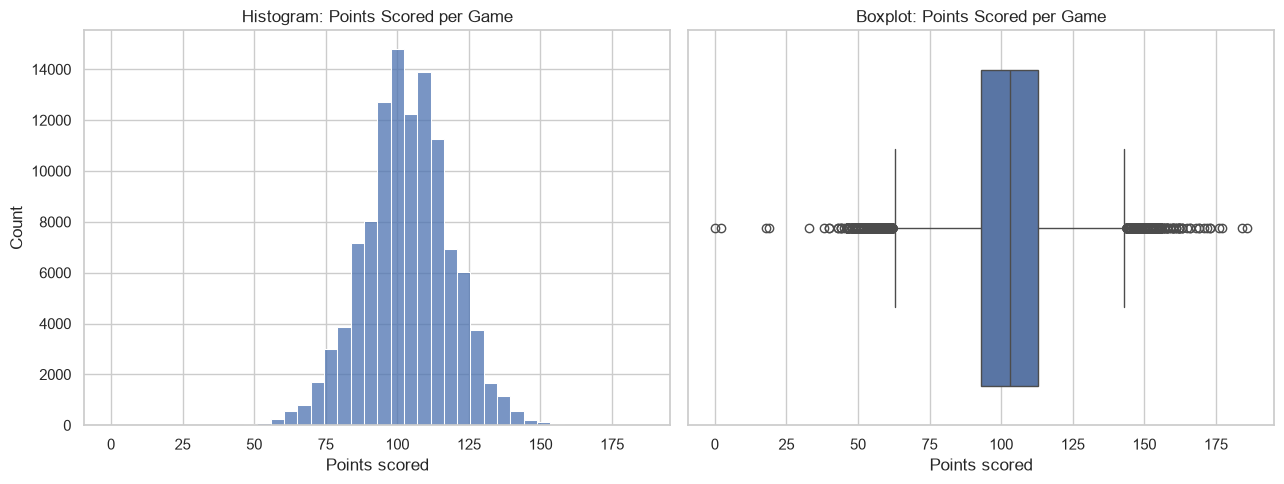

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["pts"], bins=40, color="#4C72B0", ax=axes[0])
axes[0].set_title("Histogram: Points Scored per Game")
axes[0].set_xlabel("Points scored")

sns.boxplot(x=df["pts"], color="#4C72B0", ax=axes[1])
axes[1].set_title("Boxplot: Points Scored per Game")
axes[1].set_xlabel("Points scored")
plt.tight_layout()
plt.show()

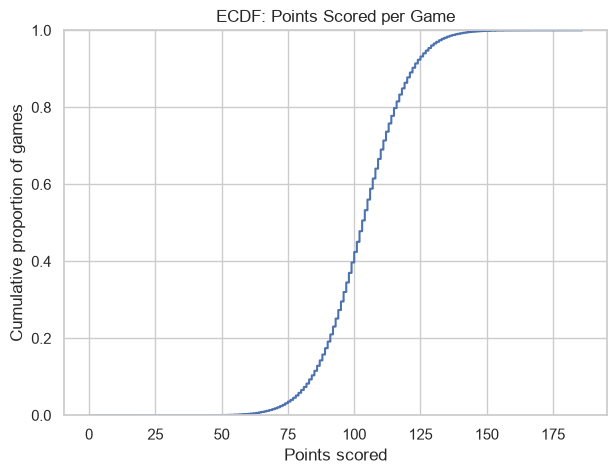

In [5]:
# Additional distribution visualization (ECDF) for pts
plt.figure(figsize=(7, 5))
sns.ecdfplot(df["pts"], color="#4C72B0")
plt.title("ECDF: Points Scored per Game")
plt.xlabel("Points scored")
plt.ylabel("Cumulative proportion of games")
plt.show()

**Interpretation — `pts`:** the typical game score is about 103 points (mean and median are almost identical: 103.23 vs 103.00), and the middle 50% of games fall between 93 and 113 points (IQR = 20). The distribution is close to symmetric (skew ≈ -0.04) — the histogram and the ECDF's smooth S-shape both confirm a roughly bell-shaped, not skewed, distribution. There are unusually high and low scores (e.g. games in the 0–60 or 150–186 range), but they are rare and roughly balanced on both sides. Because the distribution is symmetric, **the mean is just as representative as the median** here.

### Variable 2: `elo_i` — team's Elo rating entering the game

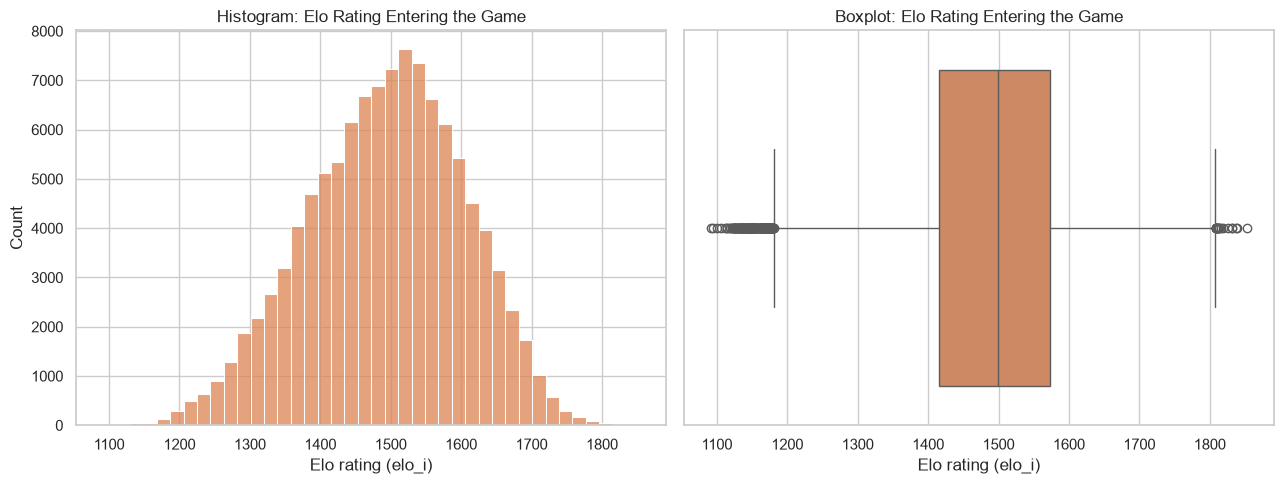

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["elo_i"], bins=40, color="#DD8452", ax=axes[0])
axes[0].set_title("Histogram: Elo Rating Entering the Game")
axes[0].set_xlabel("Elo rating (elo_i)")

sns.boxplot(x=df["elo_i"], color="#DD8452", ax=axes[1])
axes[1].set_title("Boxplot: Elo Rating Entering the Game")
axes[1].set_xlabel("Elo rating (elo_i)")
plt.tight_layout()
plt.show()

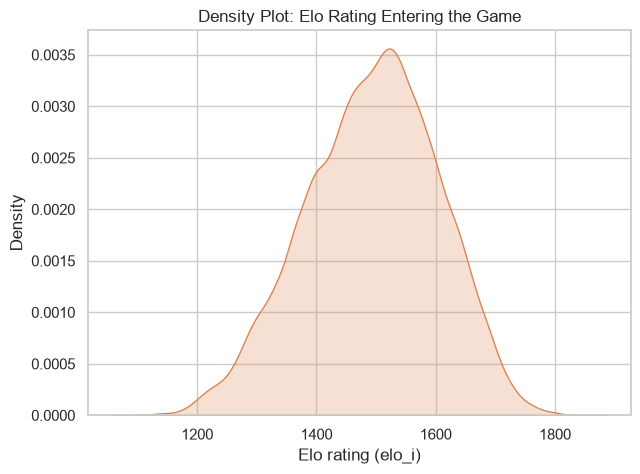

In [7]:
# Additional distribution visualization (density plot) for elo_i
plt.figure(figsize=(7, 5))
sns.kdeplot(df["elo_i"], color="#DD8452", fill=True)
plt.title("Density Plot: Elo Rating Entering the Game")
plt.xlabel("Elo rating (elo_i)")
plt.show()

**Interpretation — `elo_i`:** the typical Elo rating is about 1499 (median), very close to the mean (1492.73) — Elo systems are built to hover around a starting value of 1500, and this shows in the data. The middle 50% of ratings sit between about 1416 and 1572 (IQR ≈ 157). The distribution is close to symmetric with only a slight negative skew (-0.20), visible as a slightly longer left tail in the density plot (a small number of historically weak teams pull the low end further than the high end pulls the top). There are some unusually low ratings (well below 1200) and unusually high ratings (above 1800), corresponding to historically bad and historically dominant teams respectively. Given the near-symmetry, **the mean and median are both reasonably representative**, though the median is very slightly more central.

### Variable 3: `abs_margin` — absolute margin of victory/defeat

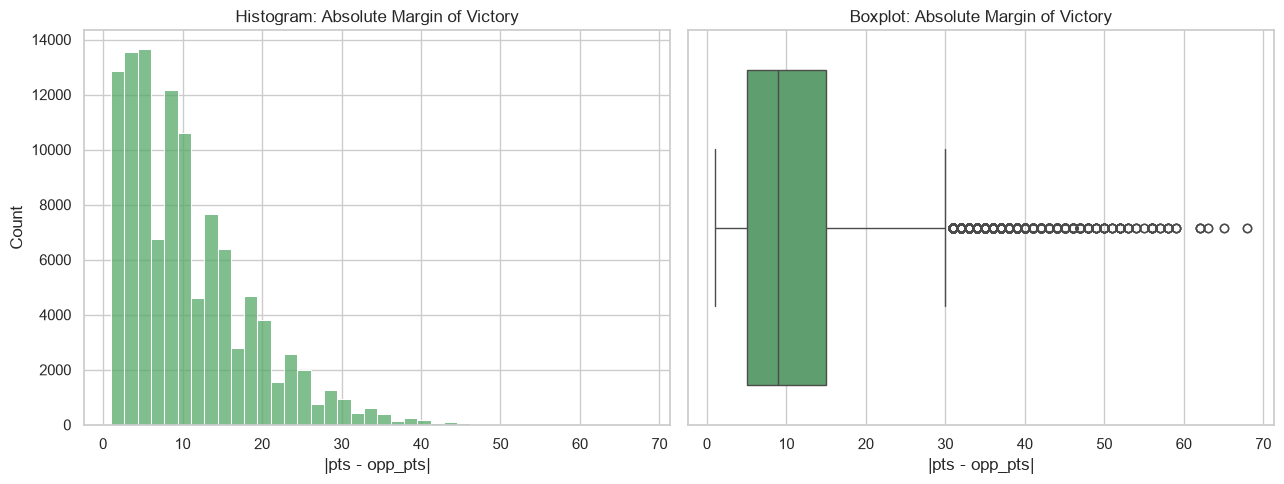

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["abs_margin"], bins=40, color="#55A868", ax=axes[0])
axes[0].set_title("Histogram: Absolute Margin of Victory")
axes[0].set_xlabel("|pts - opp_pts|")

sns.boxplot(x=df["abs_margin"], color="#55A868", ax=axes[1])
axes[1].set_title("Boxplot: Absolute Margin of Victory")
axes[1].set_xlabel("|pts - opp_pts|")
plt.tight_layout()
plt.show()

**Interpretation — `abs_margin`:** the typical game is decided by about 9 points (median), but the mean (10.73) is noticeably higher — a first sign of right skew, confirmed by the skewness statistic (≈ 1.26, the largest of the three variables). The middle 50% of games are decided by 5–15 points (IQR = 10), but the distribution has a long right tail reaching all the way to 68 points (blowout games). This is clearly **not symmetric**: most games are close, but a minority of lopsided games pull the mean upward and create many boxplot points beyond the whiskers. Because of this skew, **the median (9 points) is the more representative "typical" value** — the mean overstates how close a "typical" game usually is.

## Part 2: Comparing Mean and Median

| Variable | Mean | Median | Difference (Mean − Median) | Interpretation |
|---|---|---|---|---|
| `pts` | 103.23 | 103.00 | 0.23 | Essentially no difference — consistent with a symmetric distribution. |
| `elo_i` | 1492.73 | 1498.82 | -6.09 | Small difference (mean slightly *below* median) — consistent with the mild negative skew from a handful of very weak historical teams. |
| `abs_margin` | 10.73 | 9.00 | 1.73 | The largest relative difference (mean is ~19% higher than the median) — consistent with strong right skew from blowout games. |

**Answers:**
1. **`abs_margin`** has the largest difference between mean and median, both in absolute terms and — more importantly — relative to its own scale (1.73 out of a median of 9, versus 0.23 out of 103 for `pts`).
2. This difference is explained by a small number of **blowout games** (margins up to 68 points) that pull the mean upward while the median, being resistant to extreme values, stays anchored near the typical game.
3. Yes — a mean noticeably above the median is a classic signature of **right (positive) skew**, which matches the computed skewness value (≈ 1.26) for `abs_margin`.
4. For `pts` and `elo_i`, the mean is a fine summary (they are close to symmetric). For `abs_margin`, the **median** better describes the "typical" game, since the mean is inflated by rare blowouts.

## Part 3: Outlier Investigation

In [9]:
def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_summary = []
for col in ["pts", "elo_i", "abs_margin"]:
    lo, hi = iqr_bounds(df[col])
    n_low = (df[col] < lo).sum()
    n_high = (df[col] > hi).sum()
    outlier_summary.append({"variable": col, "lower_bound": lo, "upper_bound": hi,
                             "n_low_outliers": n_low, "n_high_outliers": n_high})

pd.DataFrame(outlier_summary)

,variable,lower_bound,upper_bound,n_low_outliers,n_high_outliers
0,pts,63.000000,143.000000,567,512
1,elo_i,1180.516888,1807.647587,180,19
2,abs_margin,-10.000000,30.000000,0,2762


The 1.5×IQR rule flags outliers on both ends for `pts` (567 low, 512 high — mostly very low- or very high-scoring games), mostly on the low end for `elo_i` (180 low, only 19 high — a long tail of historically weak teams), and **only on the high end** for `abs_margin` (0 low, 2,762 high) — which makes sense, since a margin can't go below 1, but blowouts can extend arbitrarily far above the typical range.

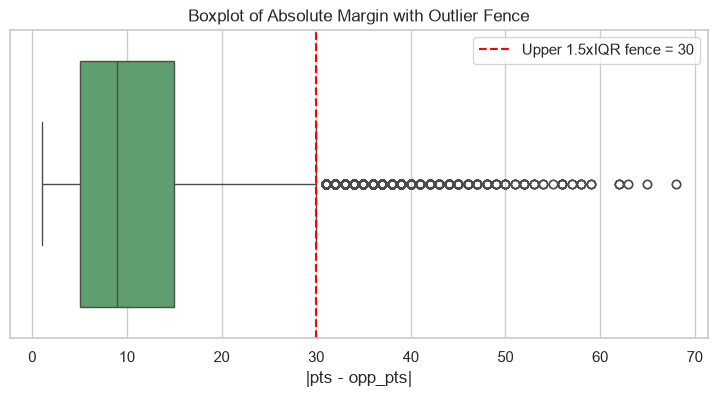

In [10]:
# Outlier-related visualization 1: boxplot of abs_margin with the IQR fence marked
lo, hi = iqr_bounds(df["abs_margin"])

plt.figure(figsize=(9, 4))
sns.boxplot(x=df["abs_margin"], color="#55A868")
plt.axvline(hi, color="red", linestyle="--", label=f"Upper 1.5xIQR fence = {hi:.0f}")
plt.title("Boxplot of Absolute Margin with Outlier Fence")
plt.xlabel("|pts - opp_pts|")
plt.legend()
plt.show()

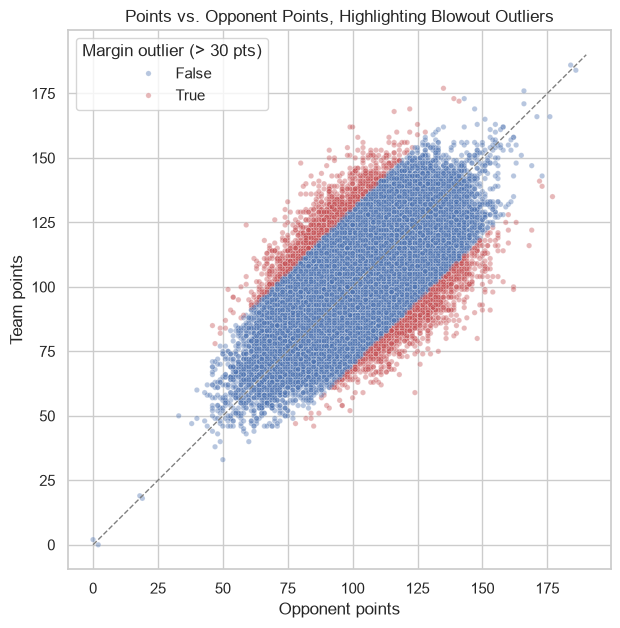

In [11]:
# Outlier-related visualization 2: scatter of pts vs opp_pts, highlighting outlier (blowout) games
df["is_margin_outlier"] = df["abs_margin"] > hi

plt.figure(figsize=(7, 7))
sns.scatterplot(
    data=df, x="opp_pts", y="pts", hue="is_margin_outlier",
    palette={False: "#4C72B0", True: "#C44E52"}, alpha=0.4, s=15,
)
plt.plot([0, 190], [0, 190], color="gray", linestyle="--", linewidth=1)
plt.title("Points vs. Opponent Points, Highlighting Blowout Outliers")
plt.xlabel("Opponent points")
plt.ylabel("Team points")
plt.legend(title="Margin outlier (> 30 pts)")
plt.show()

**How to read this plot:** each point is one team's game; the diagonal line marks an equal score. Points far above or below the diagonal represent large scoring gaps. Red points (flagged by the 1.5×IQR rule as margin outliers, i.e. decided by more than 30 points) sit clearly away from the diagonal, confirming that the rule is correctly isolating genuine blowouts rather than ordinary close games.

In [12]:
# Investigating specific potential outliers in the original data
print("Outlier 1: the single 0-point game (pts low outlier)")
print(df[df["pts"] == 0][["date_game", "team_id", "pts", "opp_id", "opp_pts", "notes"]])
print()

print("Outlier 2: the highest-scoring game on record (pts high outlier)")
print(df.nlargest(2, "pts")[["date_game", "team_id", "pts", "opp_id", "opp_pts"]])
print()

print("Outlier 3: the largest blowout on record (abs_margin high outlier)")
print(df.nlargest(2, "abs_margin")[["date_game", "team_id", "pts", "opp_id", "opp_pts", "abs_margin"]])
print()

print("Outlier 4: the highest Elo rating on record (elo_i high outlier)")
print(df.nlargest(3, "elo_i")[["date_game", "team_id", "elo_i", "year_id"]])

Outlier 1: the single 0-point game (pts low outlier)
        date_game team_id  pts opp_id  opp_pts                           notes
26684  10/26/1972     DNR    0    VIR        2  at Richmond VA; forfeit to VIR

Outlier 2: the highest-scoring game on record (pts high outlier)
        date_game team_id  pts opp_id  opp_pts
50094  12/13/1983     DET  186    DEN      184
50095  12/13/1983     DEN  184    DET      186

Outlier 3: the largest blowout on record (abs_margin high outlier)
        date_game team_id  pts opp_id  opp_pts  abs_margin
67232  12/17/1991     CLE  148    MIA       80          68
67233  12/17/1991     MIA   80    CLE      148          68

Outlier 4: the highest Elo rating on record (elo_i high outlier)
       date_game team_id      elo_i  year_id
78592  6/12/1996     CHI  1853.1045     1996
78591   6/9/1996     CHI  1838.7209     1996
78588   6/7/1996     CHI  1836.6647     1996


**Discussion of each selected outlier:**

1. **0-point game (10/26/1972, Denver Rockets vs. Virginia Squires).** `notes` explains this was a **forfeit**, not a genuinely played game — the value is technically "possible" in the sense that it's recorded correctly, but it does not represent real basketball performance. *Decision: flag and exclude from any analysis of typical scoring* (e.g. when computing "how many points does a team usually score"), since it isn't a real observation of gameplay, but keep it in the dataset since it is a real, correctly-recorded historical event for other purposes (e.g. counting forfeits).

2. **186-point game (12/13/1983, Detroit Pistons vs. Denver Nuggets, 186–184).** This is a real, well-documented NBA record — the highest-scoring game in NBA history, decided in triple overtime. The value is plausible once you know the game went to multiple overtimes (more overtime periods → more total points). *Decision: keep* — it is a genuine, historically verified observation, not an error.

3. **68-point blowout (12/17/1991, Cleveland Cavaliers 148 – Miami Heat 80).** Also a real, documented result — one of the largest margins of victory in NBA history. *Decision: keep* — an unusual but genuine and explainable observation (a badly mismatched pair of teams that season).

4. **Elo rating ≈ 1853 (Chicago Bulls, June 1996).** This is explained by another variable: `year_id` = 1996, the year of the historic 72–10 Chicago Bulls, one of the most dominant regular-season teams ever. *Decision: keep* — the extreme value is fully explained by genuine, exceptional team performance, not a data problem.

None of the four investigated values look like data-entry errors — three are genuine extreme sporting achievements, and one (the forfeit) is a real event that simply doesn't belong in a "typical scoring" analysis. This is exactly why good EDA practice warns against automatically deleting outliers: three of these four are the *most analytically interesting* rows in the dataset, not mistakes.

## Part 4: Robust Statistics

In [13]:
robust_comparison = pd.DataFrame({
    "mean": [df["pts"].mean(), df["elo_i"].mean(), df["abs_margin"].mean()],
    "std": [df["pts"].std(), df["elo_i"].std(), df["abs_margin"].std()],
    "median": [df["pts"].median(), df["elo_i"].median(), df["abs_margin"].median()],
    "IQR": [
        df["pts"].quantile(0.75) - df["pts"].quantile(0.25),
        df["elo_i"].quantile(0.75) - df["elo_i"].quantile(0.25),
        df["abs_margin"].quantile(0.75) - df["abs_margin"].quantile(0.25),
    ],
}, index=["pts", "elo_i", "abs_margin"])
robust_comparison

,mean,std,median,IQR
pts,103.229049,15.104216,103.0000,20.000000
elo_i,1492.730380,111.434163,1498.8205,156.782675
abs_margin,10.733873,7.947202,9.0000,10.000000


In [14]:
# Demonstration: what happens to mean/std if we drop the most extreme abs_margin values?
trimmed = df[df["abs_margin"] <= hi]  # remove the 2,762 flagged blowout outliers

print("abs_margin -- ALL games:")
print(f"  mean={df['abs_margin'].mean():.2f}, std={df['abs_margin'].std():.2f}, "
      f"median={df['abs_margin'].median():.2f}, IQR={df['abs_margin'].quantile(.75)-df['abs_margin'].quantile(.25):.2f}")
print("abs_margin -- WITHOUT the flagged outlier games:")
print(f"  mean={trimmed['abs_margin'].mean():.2f}, std={trimmed['abs_margin'].std():.2f}, "
      f"median={trimmed['abs_margin'].median():.2f}, IQR={trimmed['abs_margin'].quantile(.75)-trimmed['abs_margin'].quantile(.25):.2f}")

abs_margin -- ALL games:
  mean=10.73, std=7.95, median=9.00, IQR=10.00
abs_margin -- WITHOUT the flagged outlier games:
  mean=10.09, std=6.87, median=9.00, IQR=9.00


**How outliers affect the mean and standard deviation:** removing just the 2,762 blowout games (2.5% of the data) from `abs_margin` pulls the mean down noticeably and shrinks the standard deviation, because both the mean and std are calculated from every squared/summed value — a handful of very large margins (up to 68) contribute disproportionately to both. The **median and IQR barely move**, because they only depend on the position/rank of values, not their exact magnitude — a margin of 68 and a margin of 31 both just count as "one value above Q3."

**Why median/IQR are more useful here:** for `abs_margin`, which is genuinely skewed by real (not erroneous) blowout games, the mean/std give a distorted sense of a "typical" and "usual spread" of game outcomes, since they are pulled by a small number of extreme-but-real games. The median (9 points) and IQR (5–15 points) describe the bulk of ordinary games far more accurately, without requiring us to throw away the genuine blowout data to get a sensible summary. For `pts` and `elo_i`, which are close to symmetric, classical and robust statistics tell essentially the same story — robustness matters most exactly when a variable is skewed, as `abs_margin` is.

## Part 5: Transformation

**Variable selected:** `abs_margin` — it is the only one of the three variables with noticeable skewness (≈ 1.26), so it's the natural candidate. A transformation might help because the raw variable's mean, standard deviation, and outlier flags are all being pulled around by a long right tail of blowout games; a transformation that compresses large values more than small ones can make the distribution easier to summarize and visualize.

**Transformation chosen:** square-root transformation (`sqrt(abs_margin)`). I compared both a log and a square-root transform; the square-root transform brought the skewness closer to zero (0.35 vs. -0.58 for the log, which overcorrected into a mild *left* skew), so it is the better fit for this particular variable.

In [15]:
df["sqrt_abs_margin"] = np.sqrt(df["abs_margin"])

before_after = pd.DataFrame({
    "abs_margin (before)": describe_variable(df["abs_margin"]),
    "sqrt_abs_margin (after)": describe_variable(df["sqrt_abs_margin"]),
})
before_after.loc["skew"] = [df["abs_margin"].skew(), df["sqrt_abs_margin"].skew()]
before_after

,abs_margin (before),sqrt_abs_margin (after)
mean,10.733873,3.053330
median,9.000000,3.000000
min,1.000000,1.000000
max,68.000000,8.246211
Q1,5.000000,2.236068
Q3,15.000000,3.872983
std,7.947202,1.187882
IQR,10.000000,1.636915
skew,1.255076,0.348946


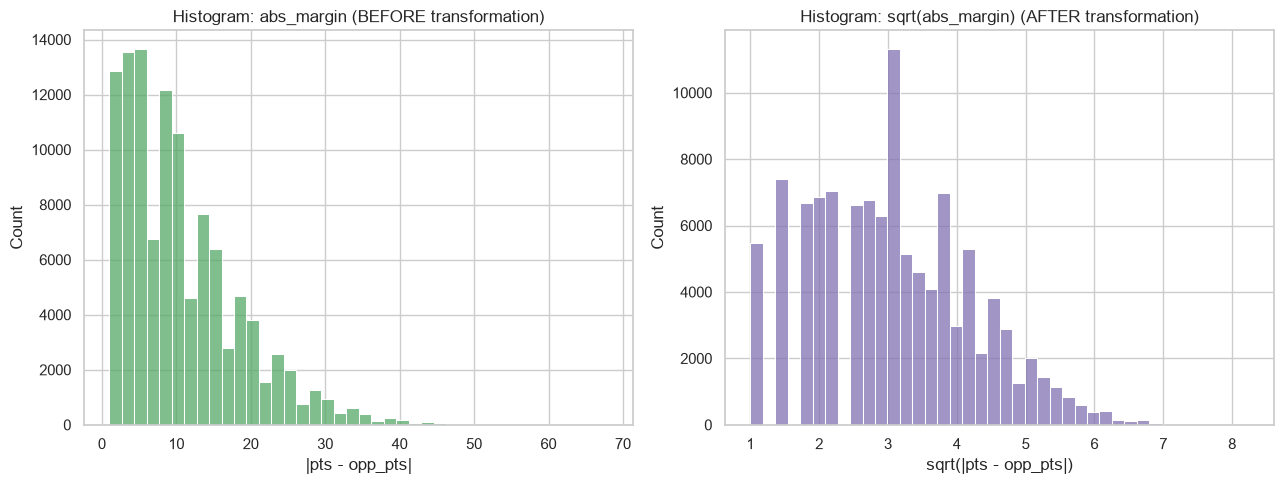

In [16]:
# 1 & 2: histograms before vs. after
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["abs_margin"], bins=40, color="#55A868", ax=axes[0])
axes[0].set_title("Histogram: abs_margin (BEFORE transformation)")
axes[0].set_xlabel("|pts - opp_pts|")

sns.histplot(df["sqrt_abs_margin"], bins=40, color="#8172B2", ax=axes[1])
axes[1].set_title("Histogram: sqrt(abs_margin) (AFTER transformation)")
axes[1].set_xlabel("sqrt(|pts - opp_pts|)")
plt.tight_layout()
plt.show()

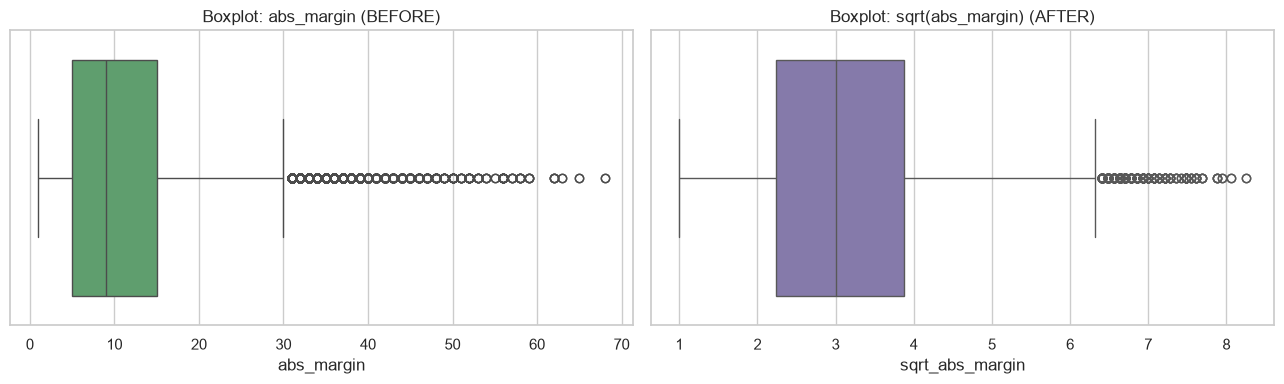

In [17]:
# 3 & 4: boxplots before vs. after
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=df["abs_margin"], color="#55A868", ax=axes[0])
axes[0].set_title("Boxplot: abs_margin (BEFORE)")

sns.boxplot(x=df["sqrt_abs_margin"], color="#8172B2", ax=axes[1])
axes[1].set_title("Boxplot: sqrt(abs_margin) (AFTER)")
plt.tight_layout()
plt.show()

In [18]:
# How many games are still flagged as outliers after the transformation?
lo_t, hi_t = iqr_bounds(df["sqrt_abs_margin"])
n_high_before = (df["abs_margin"] > hi).sum()
n_high_after = (df["sqrt_abs_margin"] > hi_t).sum()
print(f"High-side outliers BEFORE transformation: {n_high_before}")
print(f"High-side outliers AFTER transformation:  {n_high_after}")

High-side outliers BEFORE transformation: 2762
High-side outliers AFTER transformation:  458


**Comparison:** the mean dropped from 10.73 to 3.05 and the median from 9.00 to 3.00 (expected, since square-rooting compresses large values), but more importantly the **relationship between them changed**: on the square-root scale the mean and median are almost equal (3.05 vs 3.00), versus a visibly larger gap on the original scale (10.73 vs 9.00). The spread (IQR) shrank from 10 to about 1.6, and — most tellingly — the number of games flagged as outliers by the 1.5×IQR rule dropped from 2,762 to 458 (about an 83% reduction). The histograms confirm this visually: the long right tail is pulled in and the shape looks much closer to symmetric, though a mild right skew (0.35) is still visible, and the boxplot after transformation shows far fewer points beyond the whiskers.

## Part 6: Interpretation of Transformation

1. **Did the transformation reduce skewness?** Yes — skewness dropped from about 1.26 to about 0.35, a reduction of roughly 72%.
2. **Did the distribution become more symmetric?** Yes, clearly, both in the skewness statistic and visibly in the histogram — though it is not perfectly symmetric; a mild right-leaning shape remains.
3. **Did the influence of extreme observations change?** Yes — the number of games flagged as outliers by the 1.5×IQR rule fell from 2,762 to 458, and the boxplot shows far fewer points beyond the whiskers. The transformation did not erase the genuine blowout games, but it substantially reduced how extreme they look relative to the rest of the data.
4. **Does the transformed variable provide a more useful representation of the data?** It depends on the purpose. For statistical summaries or as an input to further modelling (e.g. correlating margin of victory with another variable without letting a handful of 60+ point blowouts dominate the result), the square-root scale is more useful. For directly communicating results to someone unfamiliar with the data ("games are typically decided by about 9 points"), the original scale is more interpretable, since "sqrt of 9 points" has no intuitive meaning on its own.
5. **Would I use the transformed variable in further analysis?** Yes, if the next step involves correlating margin of victory with another numerical variable (e.g. `elo_i` difference) or fitting a model that assumes roughly symmetric, homogeneous-variance inputs — the transformed variable behaves better for that purpose. I would keep the original `abs_margin` for any purely descriptive reporting, since it stays in an interpretable unit (points).

## Part 7: What Have You Learned?

**Revisiting an Part 1 question:** *"Do home teams have an advantage over away teams, in both win rate and points scored?"* In Part 1 I found home teams win about 62.6% of games and score a few more points on average. The distribution work in Part 2 refines this: `abs_margin` is right-skewed with a median of only 9 points, meaning **most games — home or away — are decided closely**, and the home-court "advantage" found in Part 1 is mostly a matter of *tipping close games* toward the home team, not a pattern of home teams routinely blowing opponents out. This reframes the original finding: home advantage is primarily about win probability in tight games, not about margin of victory.

**New questions raised by this analysis:**

1. Does the distribution of `abs_margin` differ between home and away games — are home wins, specifically, less likely to be blowouts than away wins?
2. Now that the ABA is known (from Part 1) to have higher average scoring, does it also show a different *skew* in `abs_margin` — were ABA games more or less prone to blowouts than NBA games?
3. Is there a relationship between the *difference* in two teams' Elo ratings before a game and the resulting `abs_margin` — do bigger Elo gaps predict bigger blowouts, not just more likely wins?
4. Since the sqrt-transformed margin still flags 458 games as outliers, are these disproportionately concentrated in certain eras, leagues, or teams (e.g. dynasty teams, expansion-era weak teams), which would connect this analysis back to the scoring-era findings from Part 1?

## Conclusion

This part shifted the analysis from *what the data looks like* (Part 1) to *how its statistical structure behaves and what that implies* (Part 2). The main distributional finding is that not all numerical variables in this dataset behave the same way: `pts` and `elo_i` are both close to symmetric, so their means are trustworthy summaries, while `abs_margin` — the absolute scoring margin — is clearly and meaningfully right-skewed (skewness ≈ 1.26), because most games are close but a genuine minority are lopsided blowouts.

`abs_margin` was both the most skewed variable and the source of the most interesting potential outliers: a forfeited 0-point game (a real event, but not a genuine scoring performance — excluded from typical-scoring analysis but kept in the dataset), the 186-point triple-overtime record game, a 68-point blowout, and the historically dominant 1996 Chicago Bulls' peak Elo rating. All were investigated individually rather than dropped automatically, and all but the forfeit were judged to be genuine, explainable extreme values worth keeping.

Robust statistics made the practical stakes of this concrete: dropping just 2.5% of games (the blowout outliers) visibly moved the mean and standard deviation of `abs_margin`, while the median and IQR barely changed — exactly the behavior that makes median/IQR preferable for skewed, real-world variables like this one. The square-root transformation of `abs_margin` was a genuine improvement for this variable specifically: skewness fell by about 72% and IQR-flagged outliers fell by 83%, though it did not fully symmetrize the distribution and is less intuitive to communicate than the original point-based scale.

Overall, my understanding of the dataset shifted from "a game log with some outliers" to a more precise picture: two of my three key variables are well-behaved, and the one that isn't (scoring margin) is skewed for a real, sports-meaningful reason — most games are close, and it is a minority of real blowouts, not data errors, that create the skew. Next, I would investigate how this skew interacts with the categorical variables from Part 1 (home/away, league, playoffs) to see whether "blowout-proneness," not just average scoring, differs meaningfully across those groups.